# Cartomize 1.0 — Des scènes à la zone d’étude

L’utilisateur choisit les **scènes**, les **bandes** et la **zone d’étude**. Cartomize mesure la couverture, sélectionne une scène suffisante ou les scènes complémentaires, harmonise les grilles, réalise une mosaïque si nécessaire et découpe au polygone.

Ce notebook permet de répéter la démonstration hors ligne. **Les pixels ci-dessous sont des données pédagogiques simulées, pas des observations satellite.** Les fichiers suivent les noms et les conventions de calibration des produits USGS Landsat Collection 2 Level-2, avec bandes, QA_PIXEL, QA_RADSAT et MTL. Les scènes utilisent volontairement deux résolutions (30 et 60 mètres).

Installer le wheel de la livraison avec l’option `[notebook]`, puis sélectionner son noyau Python.

In [1]:
%matplotlib inline
from pathlib import Path
import importlib.util
import tempfile
import json
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from shapely.geometry import box
import cartomize as cm

# Fonctionne depuis le dépôt ou depuis le dossier décompressé de la livraison.
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "examples/create_imagery_demo.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis le dossier de la livraison, avec son sous-dossier examples.")
spec = importlib.util.spec_from_file_location("imagery_demo", root / "examples/create_imagery_demo.py")
helper = importlib.util.module_from_spec(spec)
spec.loader.exec_module(helper)
outputs = Path.cwd() / "outputs"
outputs.mkdir(exist_ok=True)
run = Path(tempfile.mkdtemp(prefix="demonstration_", dir=outputs))
inputs = helper.create_demo(run / "entrees")
print("Cartomize :", cm.__version__)
print("Données pédagogiques :", inputs["scenes_directory"])
print("Zone pour la mosaïque :", inputs["zones"]["mosaic"])

Cartomize : 1.0
Données pédagogiques : tutorials/outputs/demonstration_h_yxstvt/entrees/scenes
Zone pour la mosaïque : tutorials/outputs/demonstration_h_yxstvt/entrees/zone_mosaic.gpkg


## 1. Observer les scènes et la zone

La zone s’étend sur deux scènes qui se recouvrent partiellement. Une seconde zone, plus petite, peut être couverte par la scène de gauche seulement. Les emprises dépassent les zones : le découpage est nécessaire dans les deux cas.

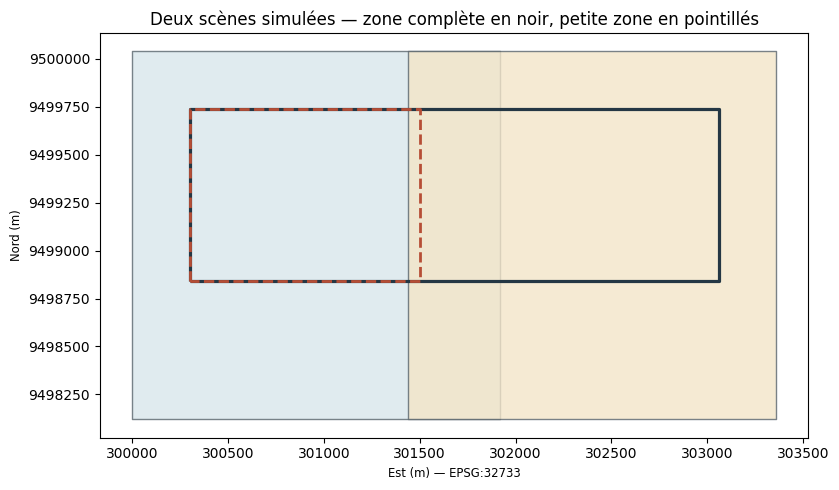

In [2]:
scenes = cm.discover_scenes(inputs["scenes_directory"])
footprints = []
for scene in scenes:
    with rasterio.open(scene.bands["red"].path) as image:
        footprints.append(box(*image.bounds))
fig, ax = plt.subplots(figsize=(10, 5))
gpd.GeoDataFrame({"scene": [s.scene_id for s in scenes]}, geometry=footprints, crs=32733).plot(
    ax=ax, color=["#d9e7ec", "#f3e5c8"], edgecolor="#59656d", alpha=.8)
gpd.read_file(inputs["zones"]["mosaic"]).boundary.plot(ax=ax, color="#243744", linewidth=2.3)
gpd.read_file(inputs["zones"]["one_scene"]).boundary.plot(ax=ax, color="#b64e36", linewidth=2, linestyle="--")
ax.set_title("Deux scènes simulées — zone complète en noir, petite zone en pointillés")
ax.set_xlabel("Est (m) — EPSG:32733")
ax.set_ylabel("Nord (m)")
ax.ticklabel_format(style="plain", useOffset=False)
plt.tight_layout()
plt.show()

## 2. Une scène suffit : choisir puis découper

Le même ensemble de fichiers est fourni, mais Cartomize détermine qu’une seule scène couvre la petite zone. Aucun choix manuel de mosaïque n’est nécessaire.

In [3]:
one = cm.preprocess_imagery(
    inputs["selected_band_paths"], run / "une_scene",
    aoi=inputs["zones"]["one_scene"],
    band_order=inputs["band_order"],
    separate_bands=True, composition="natural",
)
assert one.report["mosaic"] is False
assert one.report["usable_percent"] == 100
print("Décision : une scène suffisante, puis découpage")
print("Scènes retenues :", one.report["selected_scene_ids"])
print("Couverture utile :", one.report["usable_percent"], "%")

Décision : une scène suffisante, puis découpage
Scènes retenues : ['LC08_L2SP_181063_20260817_20260820_02_T1']
Couverture utile : 100.0 %


## 3. Deux scènes sont nécessaires : harmoniser, mosaïquer puis découper

Les mêmes bandes sont sélectionnées pour la zone plus étendue. Le moteur choisit automatiquement une grille commune ; avec ces entrées 30/60 mètres, la résolution automatique est 60 mètres. Il applique les masques et la calibration, réalise la mosaïque et découpe les sorties. Les valeurs scientifiques restent distinctes de la composition d’affichage.

Projection : EPSG:32733
Résolution : (60.0, 60.0)
Dimensions : 46 × 15
Bandes : ('blue', 'green', 'red', 'nir', 'swir1', 'swir2')
Couverture utile : 100.0 %
Rapport : tutorials/outputs/demonstration_h_yxstvt/mosaique/preprocessing.json


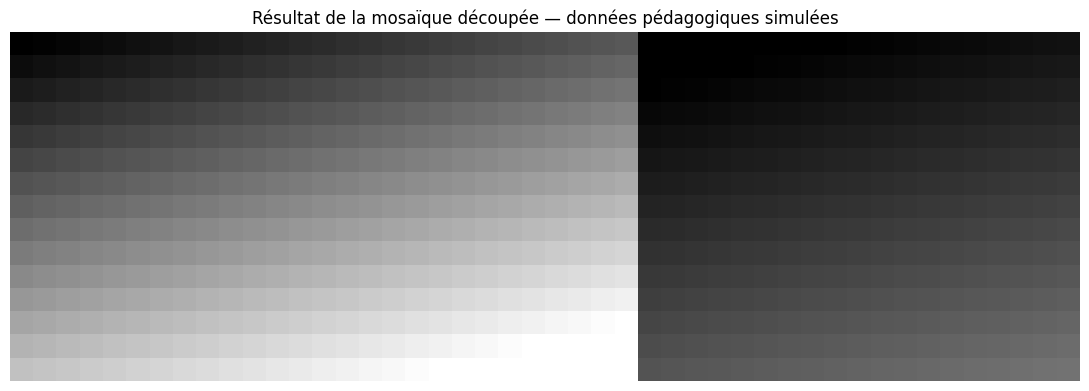

In [4]:
mosaic = cm.preprocess_imagery(
    inputs["selected_band_paths"], run / "mosaique",
    aoi=inputs["zones"]["mosaic"],
    band_order=inputs["band_order"],
    separate_bands=True, composition="natural",
)
assert mosaic.report["mosaic"] is True
assert mosaic.report["usable_percent"] == 100
product = mosaic.products[0]
with rasterio.open(product["multiband"]) as image:
    print("Projection :", image.crs)
    print("Résolution :", image.res)
    print("Dimensions :", image.width, "×", image.height)
    print("Bandes :", image.descriptions)
print("Couverture utile :", mosaic.report["usable_percent"], "%")
print("Rapport :", mosaic.manifest)
with rasterio.open(product["composition"]) as rgb:
    display = np.moveaxis(rgb.read(), 0, -1)
fig, ax = plt.subplots(figsize=(11, 4))
ax.imshow(display)
ax.set_title("Résultat de la mosaïque découpée — données pédagogiques simulées")
ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Une scène manque : localiser les lacunes

En fournissant seulement la scène de gauche pour la grande zone, la couverture ne peut pas être complète. Cartomize conserve le diagnostic et une carte des secteurs manquants pour guider l’ajout de scènes. Aucune valeur n’est créée pour combler les données absentes.

Couverture utile : 58.7 %
Action proposée : additional_scenes
Carte des lacunes : tutorials/outputs/demonstration_h_yxstvt/couverture_incomplete_diagnostic/gaps.tif


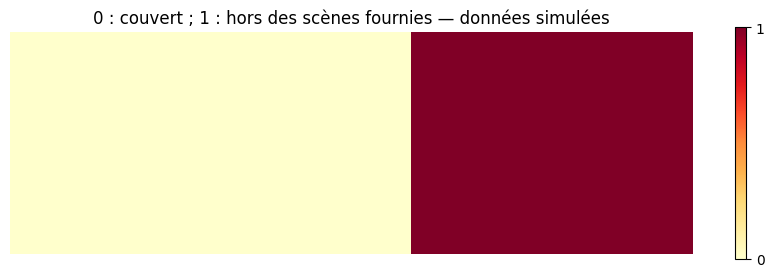

In [5]:
try:
    cm.preprocess_imagery(
        inputs["scene_directories"][0], run / "couverture_incomplete",
        aoi=inputs["zones"]["mosaic"],
        band_order=inputs["band_order"],
    )
except cm.ImageryCoverageError as error:
    print("Couverture utile :", round(error.report["usable_percent"], 2), "%")
    print("Action proposée :", error.report["recommended_action"])
    print("Carte des lacunes :", error.diagnostic.gaps)
    with rasterio.open(error.diagnostic.gaps) as gaps:
        values = gaps.read(1, masked=True)
    fig, ax = plt.subplots(figsize=(11, 4))
    view = ax.imshow(values, cmap="YlOrRd", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title("0 : couvert ; 1 : hors des scènes fournies — données simulées")
    ax.axis("off")
    fig.colorbar(view, ax=ax, ticks=[0, 1], shrink=.75)
    plt.show()
else:
    raise AssertionError("Cette sélection pédagogique doit présenter une lacune.")

## 5. Passer à l’interface ou à vos scènes USGS

Dans l’interface, ouvrir **Prétraitement multispectral**, conserver **Automatique : contrôler et préparer**, sélectionner le dossier `scenes` indiqué au début puis la zone `zone_mosaic.gpkg`. Choisir un nouveau dossier de sortie et cliquer **Exécuter**. Le moteur est le même que dans les cellules précédentes.

Pour ouvrir une fenêtre depuis un notebook local, exécuter `cm.launch()` dans une nouvelle cellule. La fenêtre s’ouvre sur l’ordinateur qui exécute Python.

Pour les données réelles, remplacer les chemins par ceux des produits **Landsat Collection 2 Level-2 extraits**, en conservant les noms de bandes, MTL et masques QA. Les scènes à dates différentes demandent une décision explicite. Le guide `docs/DEMONSTRATION_1.0.md` détaille le parcours et les autres situations (nuages, NoData, scènes complémentaires).